# 9. Naive Bayes

Bayes' rule with the "naive" assumption that features are independent given the class:
`P(default | x) ~ P(default) * prod_j P(x_j | default)`. Each feature is cut into 10 bins and the
per-class bin frequencies are counted (categorical Naive Bayes, Laplace smoothing).

From-scratch code: `ClassificationAlgorithms/NaiveBayes.py` · charts: `Images/Classification/09_Naive_Bayes/` · tables: `Results/Classification/09_Naive_Bayes/`

## 1. Setup and data

In [1]:
# Setup: imports, data and the fixed 60/20/20 train/validation/test split (seed 42)
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Common")))

import numpy as np
from project import Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from NaiveBayes import NaiveBayesScratch
from sklearn.naive_bayes import CategoricalNB, GaussianNB
import plots

out = Outputs("Classification", "09_Naive_Bayes")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. Model

In [2]:
# Model: build the from-scratch model and train it
model = NaiveBayesScratch(kind="categorical", n_bins=10)
check_settings("Naive Bayes", model)
model.fit(d.X_tr, d.y_tr, feature_names=d.feature_cols)
p_te = model.predict_proba(d.X_te)[:, 1]

# verification 1: categorical NB vs scikit-learn CategoricalNB on the same bins
binned = lambda A: np.column_stack([np.searchsorted(model.edges_[j], A[:, j], side="right") for j in range(A.shape[1])])
sk = CategoricalNB(alpha=1.0, min_categories=[len(e) + 1 for e in model.edges_]).fit(binned(d.X_tr), d.y_tr)
p_sk = sk.predict_proba(binned(d.X_te))[:, 1]
check = [
    sklearn_check(
        "Naive Bayes (categorical) vs CategoricalNB",
        np.abs(p_te - p_sk).max(),
        roc_auc(d.y_te, p_te),
        roc_auc(d.y_te, p_sk),
        "max |dP|",
    )
]

# verification 2: the Gaussian flavour vs GaussianNB
nbg = NaiveBayesScratch(kind="gaussian").fit(d.X_tr, d.y_tr, feature_names=d.feature_cols)
gk = GaussianNB().fit(d.X_tr, d.y_tr)
check.append(
    sklearn_check(
        "Naive Bayes (Gaussian) vs GaussianNB",
        np.abs(nbg.predict_proba(d.X_te)[:, 1] - gk.predict_proba(d.X_te)[:, 1]).max(),
        roc_auc(d.y_te, nbg.predict_proba(d.X_te)[:, 1]),
        roc_auc(d.y_te, gk.predict_proba(d.X_te)[:, 1]),
        "max |dP|",
    )
)

settings match Common/model_zoo.py (5 values checked)


## 3. Results

                                  test set  at plain 0.5
threshold (chosen on validation)    0.0363        0.5000
log loss                            0.6568           NaN
accuracy                            0.4656        0.7390
precision                           0.2070        0.2695
recall / sensitivity                0.8328        0.3738
specificity                         0.3960           NaN
F1                                  0.3316        0.3132
ROC-AUC                             0.6756           NaN
PR-AUC                              0.2629           NaN
defaulters missed (FN)             51.0000           NaN

catches 83.3% of the 305 test defaulters (51 missed), flags 64.0% of applicants


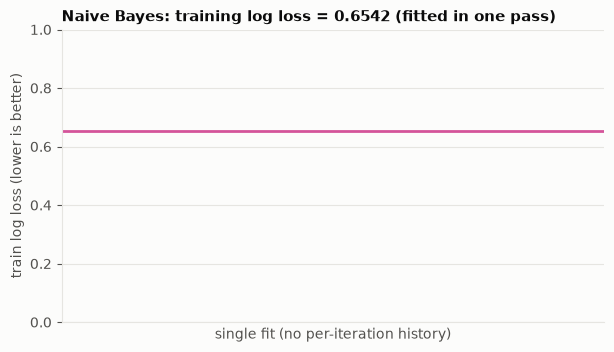

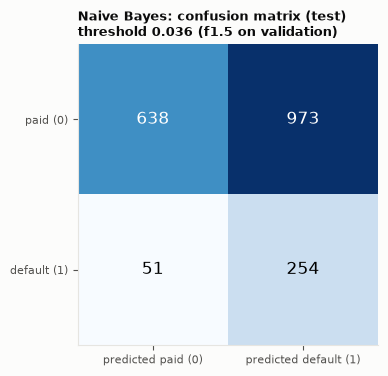

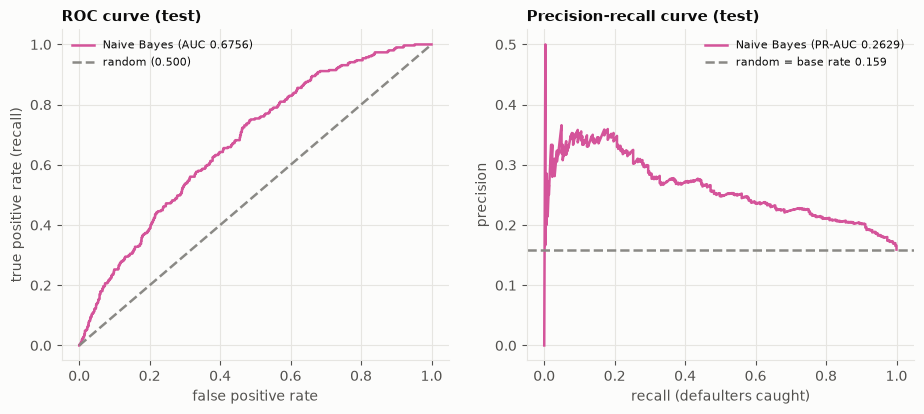

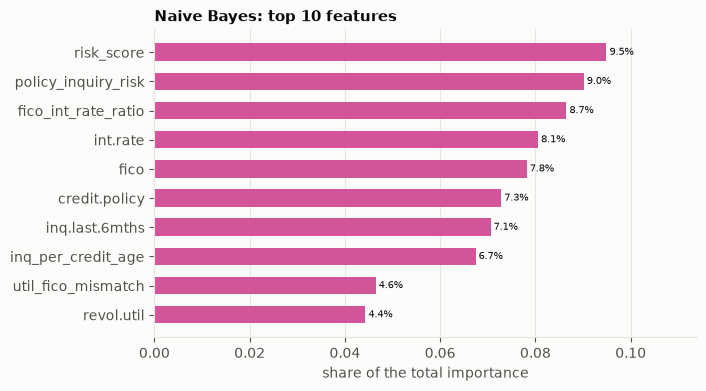


scratch vs library:
  Naive Bayes (categorical) vs CategoricalNB
    AUC scratch 0.6756 | AUC library 0.6756 | max |dP| = 1.77e-14
  Naive Bayes (Gaussian) vs GaussianNB
    AUC scratch 0.6749 | AUC library 0.6749 | max |dP| = 1.41e-14

saved + reloaded TrainedModels/Classification/09_Naive_Bayes.joblib (identical predictions: True)


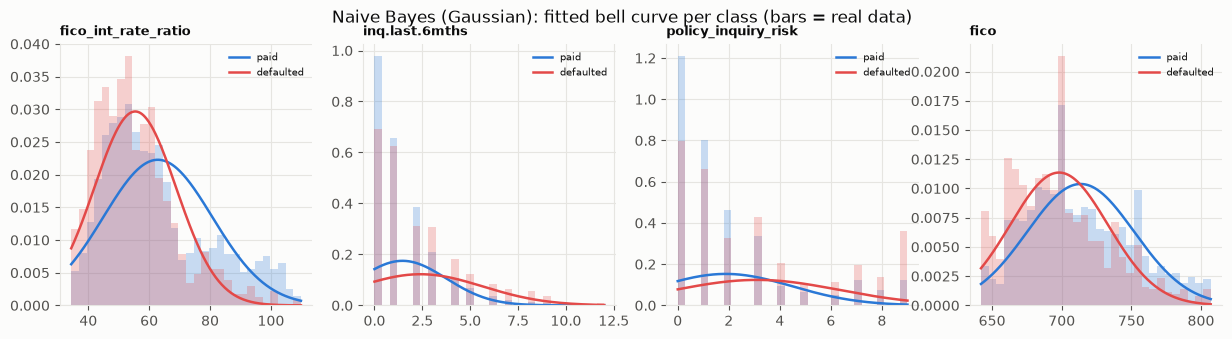

In [3]:
# Results: metrics at the validation-chosen threshold, charts, scratch-vs-library check, saved model
row = report_classifier(out, "Naive Bayes", model, d, check)

# what the Gaussian flavour multiplies together: one fitted bell curve per class and feature
top = np.argsort(-nbg.feature_importances_)[:4]
fig, axes = plots.plt.subplots(1, 4, figsize=(15, 3.4))
for ax, j in zip(axes, top):
    xs = np.linspace(np.percentile(d.X_tr[:, j], 0.5), np.percentile(d.X_tr[:, j], 99.5), 300)
    for c, col, lab in ((0, plots.BLUE, "paid"), (1, plots.RED, "defaulted")):
        ax.hist(d.X_tr[d.y_tr == c, j], bins=30, range=(xs[0], xs[-1]), density=True, alpha=0.25, color=col)
        ax.plot(
            xs,
            np.exp(-0.5 * (xs - nbg.theta_[c, j]) ** 2 / nbg.var_[c, j]) / np.sqrt(2 * np.pi * nbg.var_[c, j]),
            color=col,
            label=lab,
        )
    ax.set_title(d.feature_cols[j], fontsize=9)
    ax.legend(fontsize=7)
fig.suptitle("Naive Bayes (Gaussian): fitted bell curve per class (bars = real data)")
plots._save(fig, out.image("gaussian_densities.png"))